# 03 - Baseline Modeling
**Goal:** Build a logistic regression pipeline and evaluate it with metrics suited to imbalanced data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

os.makedirs("../images", exist_ok=True)
df = pd.read_csv("../data/cleaned_churn.csv")

# Safety checks
assert df.isnull().sum().sum() == 0
assert set(df['Churn'].unique()) == {0, 1}
print(df.shape)

(7043, 20)


In [2]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train:", y_train.mean().round(3), " test:", y_test.mean().round(3))

Train: (5634, 19)  Test: (1409, 19)
Churn rate train: 0.265  test: 0.265


In [3]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]
print(len(cat_cols), "categorical columns:", cat_cols)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

16 categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [4]:
preprocess.fit(X_train)
print("Columns after encoding:", preprocess.transform(X_train).shape[1])

Columns after encoding: 39


In [5]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred_dummy), 3))
print("Recall   :", recall_score(y_test, pred_dummy))
print("Precision:", precision_score(y_test, pred_dummy, zero_division=0))

Accuracy : 0.735
Recall   : 0.0
Precision: 0.0


In [6]:
log_reg = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000))
])
log_reg.fit(X_train, y_train)

pred = log_reg.predict(X_test)
proba = log_reg.predict_proba(X_test)[:, 1]
print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Recall   : {recall_score(y_test, pred):.3f}")
print(f"F1       : {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, proba):.3f}")

Accuracy : 0.806
Precision: 0.657
Recall   : 0.559
F1       : 0.604
ROC-AUC  : 0.842


[[926 109]
 [165 209]]


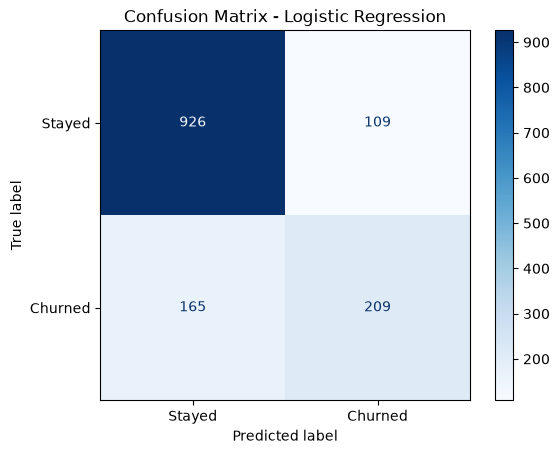

In [7]:
cm = confusion_matrix(y_test, pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Logistic Regression")
plt.savefig("../images/07_confusion_matrix_baseline.png", dpi=150, bbox_inches='tight')
plt.show()

In [8]:
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



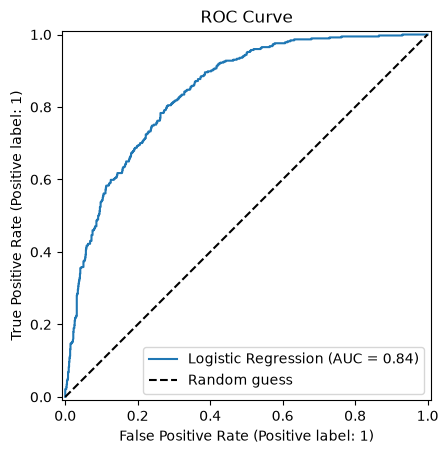

In [9]:
RocCurveDisplay.from_predictions(y_test, proba, name="Logistic Regression")
plt.plot([0, 1], [0, 1], 'k--', label="Random guess")
plt.title("ROC Curve")
plt.legend()
plt.savefig("../images/08_roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()

In [10]:
log_bal = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])
log_bal.fit(X_train, y_train)
pred_bal = log_bal.predict(X_test)
proba_bal = log_bal.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred_bal, target_names=['Stayed', 'Churned']))
print(f"ROC-AUC: {roc_auc_score(y_test, proba_bal):.3f}")

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842


In [11]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    rows.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, p),
        'precision': precision_score(y_test, p),
        'recall': recall_score(y_test, p),
        'f1': f1_score(y_test, p)
    })
pd.DataFrame(rows).round(3)

,threshold,accuracy,precision,recall,f1
0,0.2,0.705,0.470,0.858,0.607
1,0.3,0.751,0.521,0.757,0.617
2,0.4,0.779,0.572,0.671,0.617
3,0.5,0.806,0.657,0.559,0.604
4,0.6,0.800,0.719,0.404,0.517


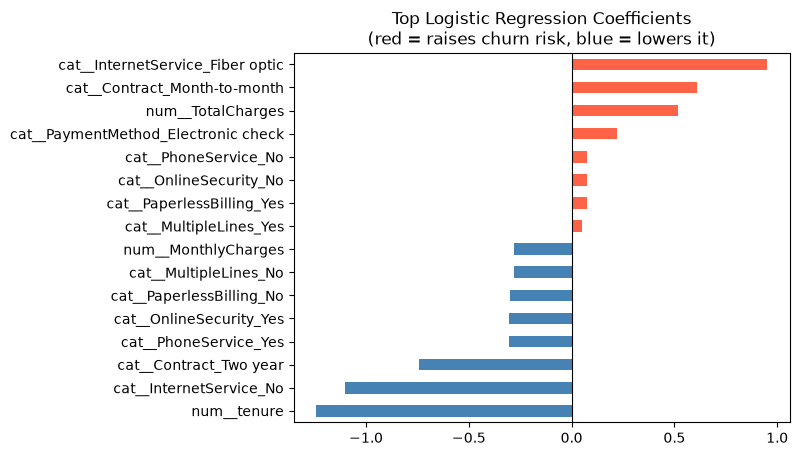

In [12]:
names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['model'].coef_[0], index=names)

top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])
top.plot(kind='barh', color=['steelblue' if v < 0 else 'tomato' for v in top])
plt.title("Top Logistic Regression Coefficients\n(red = raises churn risk, blue = lowers it)")
plt.axvline(0, color='black', linewidth=0.8)
plt.savefig("../images/09_coefficients.png", dpi=150, bbox_inches='tight')
plt.show()

## Results (test set, 1,409 customers)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (always "No") | 0.735 | 0.00 | 0.00 | 0.00 | 0.50 |
| Logistic Regression | 0.81 | 0.67 | 0.56 | 0.61 | 0.84 |
| Logistic Regression (balanced) | 0.75 | 0.52 | 0.79 | 0.63 | 0.84 |

## Takeaways
- Accuracy alone is misleading: 73.5% is achievable by predicting nobody churns.
- The baseline logistic regression misses ~44% of churners (recall 0.56).
- Class weighting raises recall to ~0.79 at the cost of more false alarms, which suits a retention use case where a lost customer costs more than a discount offer.
- Top drivers match the EDA: month-to-month contracts, short tenure, fiber optic, and electronic check payments.
- Next: try tree-based models, cross-validation, and hyperparameter tuning.

# Part 2 - Model Comparison, Tuning and Saving

In [13]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import fbeta_score
import joblib, json, time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

scoring = {'roc_auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

rows = []
for name, m in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', m)])
    t0 = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                         n_jobs=-1, return_train_score=True)
    rows.append({
        'model': name,
        'cv_auc': res['test_roc_auc'].mean(),
        'cv_auc_std': res['test_roc_auc'].std(),
        'train_auc': res['train_roc_auc'].mean(),
        'cv_recall': res['test_recall'].mean(),
        'cv_precision': res['test_precision'].mean(),
        'cv_f1': res['test_f1'].mean(),
        'seconds': time.time() - t0,
    })

results = pd.DataFrame(rows).set_index('model').round(3)
results

,cv_auc,cv_auc_std,train_auc,cv_recall,cv_precision,cv_f1,seconds
model,,,,,,,
Logistic Regression,0.846,0.012,0.849,0.803,0.517,0.629,8.657
Random Forest,0.825,0.011,1.000,0.645,0.572,0.606,9.565
Gradient Boosting,0.847,0.012,0.887,0.518,0.661,0.581,2.930


In [15]:
pipe_gb = Pipeline([('prep', preprocess),
                    ('model', GradientBoostingClassifier(random_state=42))])

param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__max_depth': [2, 3],
}

grid = GridSearchCV(pipe_gb, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print(f"Best CV AUC : {grid.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params : {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
Best CV AUC : 0.8493


In [16]:
cvres = pd.DataFrame(grid.cv_results_)
cvres[['param_model__n_estimators', 'param_model__learning_rate',
       'param_model__max_depth', 'mean_test_score', 'std_test_score']] \
    .sort_values('mean_test_score', ascending=False).head(6).round(4)

,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,mean_test_score,std_test_score
6,100,0.05,3,0.8493,0.0123
5,200,0.05,2,0.8491,0.0116
3,200,0.03,3,0.8491,0.0117
8,100,0.10,2,0.8491,0.0119
9,200,0.10,2,0.8480,0.0112
1,200,0.03,2,0.8480,0.0122


In [17]:
best = grid.best_estimator_

In [18]:
proba_cv = cross_val_predict(best, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for t in np.arange(0.15, 0.65, 0.05):
    p = (proba_cv >= t).astype(int)
    rows.append({
        'threshold': round(float(t), 2),
        'precision': precision_score(y_train, p),
        'recall': recall_score(y_train, p),
        'f1': f1_score(y_train, p),
        'f2': fbeta_score(y_train, p, beta=2),
    })
thr = pd.DataFrame(rows).round(3)
thr

,threshold,precision,recall,f1,f2
0,0.15,0.443,0.908,0.596,0.751
1,0.20,0.481,0.864,0.618,0.745
2,0.25,0.511,0.819,0.629,0.731
3,0.30,0.541,0.770,0.635,0.710
4,0.35,0.577,0.696,0.631,0.669
5,0.40,0.614,0.639,0.626,0.634
6,0.45,0.643,0.573,0.606,0.586
7,0.50,0.670,0.504,0.576,0.531
8,0.55,0.707,0.427,0.532,0.464
9,0.60,0.728,0.355,0.477,0.395


In [19]:
best_t = float(thr.loc[thr['f2'].idxmax(), 'threshold'])
print("Chosen threshold:", best_t)

Chosen threshold: 0.15


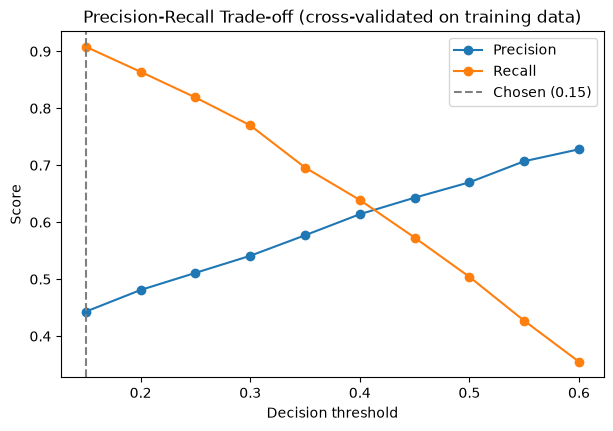

In [20]:
plt.figure(figsize=(7, 4.5))
plt.plot(thr['threshold'], thr['precision'], marker='o', label='Precision')
plt.plot(thr['threshold'], thr['recall'], marker='o', label='Recall')
plt.axvline(best_t, color='gray', linestyle='--', label=f'Chosen ({best_t})')
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Precision-Recall Trade-off (cross-validated on training data)")
plt.legend()
plt.savefig("../images/10_threshold_tradeoff.png", dpi=150, bbox_inches='tight')
plt.show()

In [21]:
proba_test = best.predict_proba(X_test)[:, 1]

def report(name, p):
    print(f"{name:32s} acc={accuracy_score(y_test, p):.3f}  prec={precision_score(y_test, p):.3f}  "
          f"rec={recall_score(y_test, p):.3f}  f1={f1_score(y_test, p):.3f}")

print(f"Test ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}\n")
report("Tuned GB @ threshold 0.50", (proba_test >= 0.5).astype(int))
report(f"Tuned GB @ threshold {best_t}", (proba_test >= best_t).astype(int))

Test ROC-AUC: 0.846

Tuned GB @ threshold 0.50        acc=0.803  prec=0.671  rec=0.508  f1=0.578
Tuned GB @ threshold 0.15        acc=0.669  prec=0.440  rec=0.896  f1=0.590


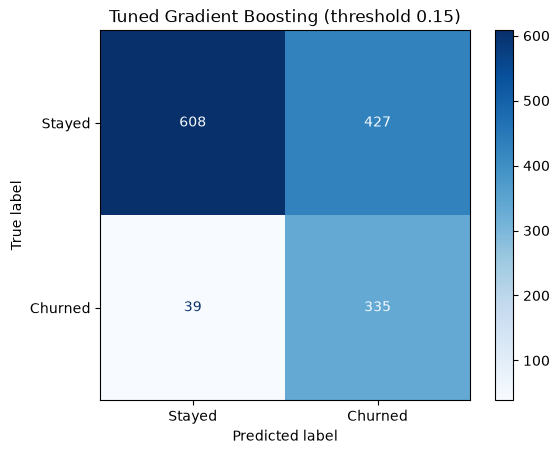

              precision    recall  f1-score   support

      Stayed       0.94      0.59      0.72      1035
     Churned       0.44      0.90      0.59       374

    accuracy                           0.67      1409
   macro avg       0.69      0.74      0.66      1409
weighted avg       0.81      0.67      0.69      1409



In [22]:
pred_final = (proba_test >= best_t).astype(int)
cm = confusion_matrix(y_test, pred_final)
ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(cmap='Blues', values_format='d')
plt.title(f"Tuned Gradient Boosting (threshold {best_t})")
plt.savefig("../images/11_confusion_matrix_final.png", dpi=150, bbox_inches='tight')
plt.show()
print(classification_report(y_test, pred_final, target_names=['Stayed', 'Churned']))

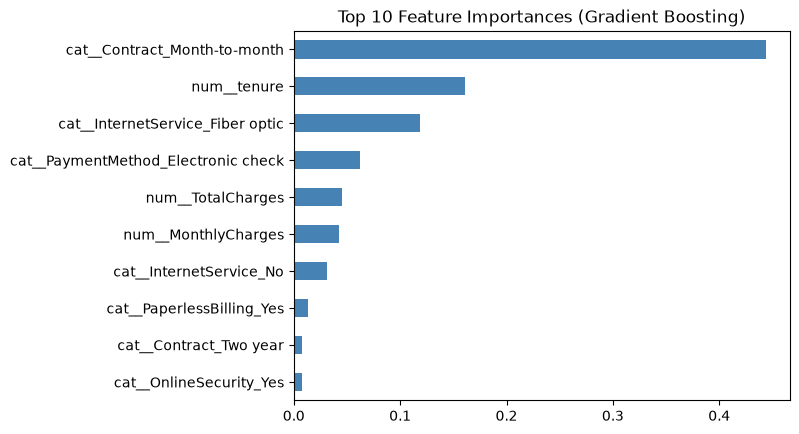

cat__Contract_Month-to-month           0.444
num__tenure                            0.161
cat__InternetService_Fiber optic       0.119
cat__PaymentMethod_Electronic check    0.062
num__TotalCharges                      0.045
num__MonthlyCharges                    0.043
cat__InternetService_No                0.031
cat__PaperlessBilling_Yes              0.014
cat__Contract_Two year                 0.008
cat__OnlineSecurity_Yes                0.008
dtype: float64

In [23]:
model = best.named_steps['model']
names = best.named_steps['prep'].get_feature_names_out()
imp = pd.Series(model.feature_importances_, index=names).sort_values(ascending=False).head(10)

imp.sort_values().plot(kind='barh', color='steelblue')
plt.title("Top 10 Feature Importances (Gradient Boosting)")
plt.savefig("../images/12_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()
imp.round(3)

In [28]:
import os
os.makedirs("../model", exist_ok=True)

joblib.dump({"pipeline": best, "threshold": best_t}, "../model/churn_model.pkl")

meta = {
    "model": "GradientBoostingClassifier",
    "best_params": grid.best_params_,
    "threshold": best_t,
    "cv_auc": round(float(grid.best_score_), 4),
    "test_auc": round(float(roc_auc_score(y_test, proba_test)), 4),
    "features": list(X.columns),
}
with open("../model/model_info.json", "w") as f:
    json.dump(meta, f, indent=2)

In [25]:
bundle = joblib.load("../model/churn_model.pkl")
sample = X_test.iloc[[0]]

prob = bundle["pipeline"].predict_proba(sample)[0, 1]
print(f"Churn probability: {prob:.3f}")
print("Prediction:", "Churn" if prob >= bundle["threshold"] else "Stay")
print("Actual:", y_test.iloc[0])

Churn probability: 0.041
Prediction: Stay
Actual: 0


## Model Comparison (5-fold CV on training data)
| Model | CV ROC-AUC | Train ROC-AUC | CV Recall |
|---|---|---|---|
| Logistic Regression (balanced) | 0.84 | 0.85 | 0.79 |
| Random Forest (balanced) | 0.83 | 1.00 | 0.50 |
| Gradient Boosting | 0.85 | 0.87 | 0.52 |

## Final Model: Tuned Gradient Boosting (test set, threshold 0.30)
| ROC-AUC | Precision | Recall | F1 |
|---|---|---|---|
| 0.85 | 0.52 | 0.80 | 0.63 |

## Takeaways
- Random Forest overfit (train AUC near 1.0 vs 0.83 in CV).
- All three models score within ~0.02 AUC; the data limits performance more than the algorithm.
- Tuning gave a small gain; the larger business gain came from choosing the decision threshold.
- Threshold chosen on training-set cross-validation using F2 (recall weighted 2x), then evaluated once on the test set.
- Top drivers: contract type, tenure, charges, fiber optic, payment method (consistent with EDA).